# Fine-Tuning LLMs - LoRA Adaptation

## Problem

Adapting a large pretrained model to a new distribution by updating every weight is costly in
memory and in storage per task. Low-Rank Adaptation (LoRA) freezes the pretrained weight matrix
and learns a low-rank update instead. This notebook implements LoRA from scratch in PyTorch and
compares it with full fine-tuning.

**Scope:** this is a *small-scale demonstration*. The model is a two-layer MLP, not an LLM. It
shows the mechanics (frozen base weight, low-rank update, parameter counts, accuracy versus
trainable parameters), not the behaviour of a transformer.

## Data

- **Source (real):** scikit-learn's bundled `load_digits` set (1,797 handwritten 8x8 digit images,
  10 classes, from the UCI optical-recognition dataset). It ships with scikit-learn, so no
  download is needed.
- **Pretraining split:** 1,000 clean images.
- **Distribution shift (applied by this notebook):** the target domain is the same digits after
  a 2-pixel horizontal shift, intensity scaled by 0.6, and Gaussian pixel noise (sigma 0.2),
  then clipped to [0, 1]. This is a covariate shift: the labels are unchanged, the inputs move.
- **Target split:** 150 labelled shifted images for adaptation, 50 for choosing the learning rate,
  and 397 held out for testing. The 200 clean images used as a source-domain check are disjoint
  from them.

## Method

**Model.** A two-layer MLP $f(x) = W_2\,\mathrm{ReLU}(W_1 x + b_1) + b_2$, with $W_1 \in
\mathbb{R}^{128\times 64}$ and $W_2 \in \mathbb{R}^{10\times 128}$.

**LoRA.** For a frozen weight $W_0 \in \mathbb{R}^{d_{out}\times d_{in}}$, LoRA learns
$A \in \mathbb{R}^{r\times d_{in}}$ and $B \in \mathbb{R}^{d_{out}\times r}$, and uses

$$
h = W_0 x + b_0 + \frac{\alpha}{r}\, B A x,
$$

with $A \sim \mathcal{N}(0, 1/d_{in})$, $B = 0$ at initialisation (so the adapted model starts
exactly at the pretrained model), $\alpha = 8$ fixed, and $W_0$, $b_0$ frozen. A layer has
$r\,(d_{in}+d_{out})$ trainable parameters. Here LoRA is applied to both linear layers, giving
$330\,r$ trainable parameters in total, against $9{,}610$ for full fine-tuning.

**Training.** Cross-entropy loss, Adam, full-batch gradient descent for 300 steps. The learning
rate is chosen from $\{10^{-3}, 3\cdot10^{-3}, 10^{-2}\}$ per method on the 50-image target
validation set, then the test set is scored once.

**Protocol.** One pretrained model (seed 0). Adaptation is repeated with 3 seeds. Reported:
trainable parameters, test accuracy (mean and standard deviation over seeds), and wall-clock
training time.

## Setup and data

In [1]:
import math, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(1)
ALPHA = 8.0

digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)          # 1797 x 64 in [0, 1]
y = digits.target.astype(np.int64)

rng = np.random.default_rng(0)
perm = rng.permutation(len(X))
src_train_idx = perm[:1000]
rest = perm[1000:]
src_test_idx = rest[:200]                             # clean, source-domain check
tgt_train_idx = rest[200:350]                         # shifted, adaptation (150)
tgt_val_idx = rest[350:400]                           # shifted, learning-rate selection (50)
tgt_test_idx = rest[400:]                             # shifted, held-out test (397)

def shift_domain(Xb, seed=1):
    img = Xb.reshape(-1, 8, 8)
    out = np.zeros_like(img)
    out[:, :, 2:] = img[:, :, :-2]                    # shift right by 2 pixels
    noise = np.random.default_rng(seed).normal(0, 0.2, size=out.shape)
    return np.clip(0.6 * out + noise, 0, 1).reshape(-1, 64).astype(np.float32)

T = lambda a: torch.tensor(a)
Xs_tr, ys_tr = T(X[src_train_idx]), T(y[src_train_idx])
Xs_te, ys_te = T(X[src_test_idx]), T(y[src_test_idx])
Xt_tr, yt_tr = T(shift_domain(X[tgt_train_idx])), T(y[tgt_train_idx])
Xt_va, yt_va = T(shift_domain(X[tgt_val_idx])), T(y[tgt_val_idx])
Xt_te, yt_te = T(shift_domain(X[tgt_test_idx])), T(y[tgt_test_idx])

print("source train / source test (clean):", len(Xs_tr), len(Xs_te))
print("target train / target val / target test (shifted):", len(Xt_tr), len(Xt_va), len(Xt_te))

source train / source test (clean): 1000 200
target train / target val / target test (shifted): 150 50 397


## LoRA layer and MLP (from scratch)

In [2]:
class LoRALinear(nn.Module):
    # Wraps a frozen nn.Linear and adds a trainable low-rank update (alpha / r) * B @ A.
    def __init__(self, base: nn.Linear, r: int, alpha: float = ALPHA):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)
        self.r = r
        self.scale = alpha / r
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))   # zero init: starts at the base model

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(64, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

def n_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Verify the LoRA layer: with B = 0 it reproduces the base layer, and the update has rank <= r.
base = nn.Linear(64, 128)
lora = LoRALinear(nn.Linear(64, 128), r=4)
lora.base.load_state_dict(base.state_dict())
x_chk = torch.randn(5, 64)
print("B=0 output equals base output:", torch.allclose(lora(x_chk), base(x_chk), atol=1e-6))
with torch.no_grad():
    lora.B.normal_()
delta = (lora.scale * lora.B @ lora.A)
print("rank of the update (r=4):", torch.linalg.matrix_rank(delta).item())
print("trainable params per LoRA layer r=4 (64->128):", n_trainable(lora), "= 4 * (64 + 128) =", 4 * (64 + 128))

B=0 output equals base output: True
rank of the update (r=4): 4
trainable params per LoRA layer r=4 (64->128): 768 = 4 * (64 + 128) = 768


## Pretraining on the source domain

In [3]:
def accuracy(model, Xb, yb):
    model.eval()
    with torch.no_grad():
        return (model(Xb).argmax(dim=1) == yb).float().mean().item()

torch.manual_seed(0)
pretrained = MLP()
opt = torch.optim.Adam(pretrained.parameters(), lr=3e-3)
t0 = time.perf_counter()
for step in range(300):
    pretrained.train()
    opt.zero_grad()
    loss = F.cross_entropy(pretrained(Xs_tr), ys_tr)
    loss.backward()
    opt.step()
pre_time = time.perf_counter() - t0
base_state = {k: v.clone() for k, v in pretrained.state_dict().items()}

print(f"pretraining: final train loss {loss.item():.4f}, time {pre_time:.2f} s")
print(f"pretrained model, source clean test accuracy : {accuracy(pretrained, Xs_te, ys_te):.4f}")
print(f"pretrained model, target shifted test accuracy (zero-shot): {accuracy(pretrained, Xt_te, yt_te):.4f}")
print(f"pretrained model, target shifted val accuracy: {accuracy(pretrained, Xt_va, yt_va):.4f}")
print("trainable params in the MLP:", n_trainable(pretrained))

pretraining: final train loss 0.0112, time 2.47 s
pretrained model, source clean test accuracy : 0.9600
pretrained model, target shifted test accuracy (zero-shot): 0.1511
pretrained model, target shifted val accuracy: 0.1800
trainable params in the MLP: 9610


## Adaptation: full fine-tuning versus LoRA at ranks 1, 2, 4, 8

Each run starts from the same pretrained weights and trains on the 150 shifted target images.
Full fine-tuning updates every parameter. LoRA freezes the base weights and trains only $A$ and
$B$ on both layers.

In [4]:
def adapt(method, r=None, lr=1e-3, seed=0, steps=300):
    torch.manual_seed(seed)
    model = MLP()
    model.load_state_dict(base_state)
    if method == "lora":
        for p in model.parameters():
            p.requires_grad_(False)
        model.fc1 = LoRALinear(model.fc1, r)
        model.fc2 = LoRALinear(model.fc2, r)
    params = [p for p in model.parameters() if p.requires_grad]
    n_tr = sum(p.numel() for p in params)
    opt = torch.optim.Adam(params, lr=lr)
    t0 = time.perf_counter()
    for _ in range(steps):
        model.train()
        opt.zero_grad()
        loss = F.cross_entropy(model(Xt_tr), yt_tr)
        loss.backward()
        opt.step()
    elapsed = time.perf_counter() - t0
    return model, n_tr, elapsed

CONFIGS = [("full", None), ("lora", 1), ("lora", 2), ("lora", 4), ("lora", 8)]
LRS = [1e-3, 3e-3, 1e-2]
SEEDS = [0, 1, 2]

def label(method, r):
    return "full fine-tune" if method == "full" else f"LoRA r={r}"

# Learning rate per method, chosen on the target validation set (mean over seeds).
best_lr = {}
val_grid = []
for method, r in CONFIGS:
    scores = {}
    for lr in LRS:
        accs = [accuracy(adapt(method, r, lr, s)[0], Xt_va, yt_va) for s in SEEDS]
        scores[lr] = float(np.mean(accs))
        val_grid.append({"method": label(method, r), "lr": lr, "val acc (mean of 3 seeds)": round(scores[lr], 4)})
    best_lr[(method, r)] = max(LRS, key=lambda lr: (scores[lr], -lr))
print(pd.DataFrame(val_grid).to_string(index=False))
print("selected learning rate:", {label(m, r): best_lr[(m, r)] for m, r in CONFIGS})

        method    lr  val acc (mean of 3 seeds)
full fine-tune 0.001                     0.5800
full fine-tune 0.003                     0.6600
full fine-tune 0.010                     0.6400
      LoRA r=1 0.001                     0.2267
      LoRA r=1 0.003                     0.3067
      LoRA r=1 0.010                     0.3800
      LoRA r=2 0.001                     0.2533
      LoRA r=2 0.003                     0.4600
      LoRA r=2 0.010                     0.4733
      LoRA r=4 0.001                     0.2733
      LoRA r=4 0.003                     0.5000
      LoRA r=4 0.010                     0.5400
      LoRA r=8 0.001                     0.3067
      LoRA r=8 0.003                     0.5200
      LoRA r=8 0.010                     0.5133
selected learning rate: {'full fine-tune': 0.003, 'LoRA r=1': 0.01, 'LoRA r=2': 0.01, 'LoRA r=4': 0.01, 'LoRA r=8': 0.003}


In [5]:
rows = []
for method, r in CONFIGS:
    lr = best_lr[(method, r)]
    tests, vals, times, n_tr = [], [], [], None
    for s in SEEDS:
        model, n_tr, elapsed = adapt(method, r, lr, s)
        tests.append(accuracy(model, Xt_te, yt_te))
        vals.append(accuracy(model, Xt_va, yt_va))
        times.append(elapsed)
    rows.append({"method": label(method, r), "trainable params": n_tr,
                 "% of full": 100.0 * n_tr / 9610, "lr": lr,
                 "test acc mean": np.mean(tests), "test acc std": np.std(tests),
                 "val acc mean": np.mean(vals), "train time s (mean)": np.mean(times)})

zero_shot = accuracy(pretrained, Xt_te, yt_te)
rows.insert(0, {"method": "zero-shot (no adaptation)", "trainable params": 0, "% of full": 0.0,
                "lr": None, "test acc mean": zero_shot, "test acc std": 0.0,
                "val acc mean": accuracy(pretrained, Xt_va, yt_va), "train time s (mean)": 0.0})
results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))

                   method  trainable params  % of full    lr  test acc mean  test acc std  val acc mean  train time s (mean)
zero-shot (no adaptation)                 0     0.0000   NaN         0.1511        0.0000        0.1800               0.0000
           full fine-tune              9610   100.0000 0.003         0.6524        0.0000        0.6600               1.2846
                 LoRA r=1               330     3.4339 0.010         0.3871        0.0260        0.3800               1.4487
                 LoRA r=2               660     6.8678 0.010         0.4467        0.0203        0.4733               1.6264
                 LoRA r=4              1320    13.7357 0.010         0.5768        0.0155        0.5400               1.7234
                 LoRA r=8              2640    27.4714 0.003         0.6079        0.0072        0.5200               1.6097


## Accuracy versus trainable parameters

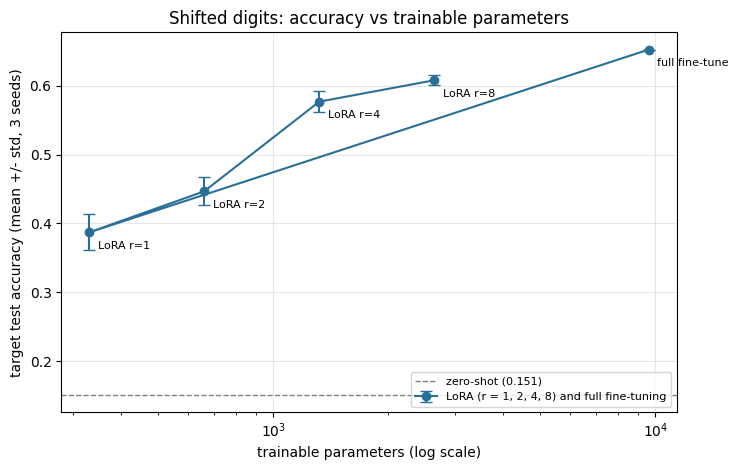

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
adapt_rows = results[results["method"] != "zero-shot (no adaptation)"]
ax.errorbar(adapt_rows["trainable params"], adapt_rows["test acc mean"], yerr=adapt_rows["test acc std"],
            fmt="o-", capsize=4, color="#2a6f97", label="LoRA (r = 1, 2, 4, 8) and full fine-tuning")
for _, rr in adapt_rows.iterrows():
    ax.annotate(rr["method"], (rr["trainable params"], rr["test acc mean"]),
                textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.axhline(zero_shot, color="grey", ls="--", lw=1, label=f"zero-shot ({zero_shot:.3f})")
ax.set_xscale("log")
ax.set_xlabel("trainable parameters (log scale)")
ax.set_ylabel("target test accuracy (mean +/- std, 3 seeds)")
ax.set_title("Shifted digits: accuracy vs trainable parameters")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## Results

In [7]:
print(results.round(4).to_string(index=False))

                   method  trainable params  % of full    lr  test acc mean  test acc std  val acc mean  train time s (mean)
zero-shot (no adaptation)                 0     0.0000   NaN         0.1511        0.0000        0.1800               0.0000
           full fine-tune              9610   100.0000 0.003         0.6524        0.0000        0.6600               1.2846
                 LoRA r=1               330     3.4339 0.010         0.3871        0.0260        0.3800               1.4487
                 LoRA r=2               660     6.8678 0.010         0.4467        0.0203        0.4733               1.6264
                 LoRA r=4              1320    13.7357 0.010         0.5768        0.0155        0.5400               1.7234
                 LoRA r=8              2640    27.4714 0.003         0.6079        0.0072        0.5200               1.6097


Small-scale demonstration: a 2-layer MLP on shifted scikit-learn digits, not an LLM. All numbers come from the executed outputs above (3 adaptation seeds, one pretrained model).

| Method | Trainable params | % of full | Learning rate | Target test acc (mean +/- std) | Train time, s (mean) |
|---|---|---|---|---|---|
| Zero-shot (no adaptation) | 0 | 0.00 | - | 0.1511 | 0 |
| Full fine-tuning | 9,610 | 100.00 | 3e-3 | 0.6524 +/- 0.0000 | 1.285 |
| LoRA r=1 | 330 | 3.43 | 1e-2 | 0.3871 +/- 0.0260 | 1.449 |
| LoRA r=2 | 660 | 6.87 | 1e-2 | 0.4467 +/- 0.0203 | 1.626 |
| LoRA r=4 | 1,320 | 13.74 | 1e-2 | 0.5768 +/- 0.0155 | 1.723 |
| LoRA r=8 | 2,640 | 27.47 | 3e-3 | 0.6079 +/- 0.0072 | 1.610 |

- **Pretraining and shift.** The pretrained MLP scores 0.9600 on clean source test images and drops to 0.1511 on the shifted target test set. The shift is severe, and adaptation has a lot to recover.
- **Accuracy rises with rank.** LoRA accuracy grows monotonically with rank (0.387, 0.447, 0.577, 0.608). At rank 8, LoRA with 27.5% of the parameters comes within 4.5 points of full fine-tuning (0.608 against 0.652).
- **Parameter counts follow the formula.** Each LoRA layer has $r(d_{in}+d_{out})$ trainable parameters, giving $330r$ in total. The check on one layer (r=4, 64 to 128) gave 768 = 4 x 192.
- **Wall-clock time did not favour LoRA.** Full fine-tuning took 1.285 s for 300 full-batch steps, and LoRA took 1.449 to 1.723 s. An earlier execution of this notebook gave 0.989 s (full) and 1.165 to 1.178 s (LoRA), so the timings are noisy on this shared machine. At this size, Python and autograd overhead dominates. LoRA's advantage here is the parameter count, not speed.

**Caveats.**
- This is an MLP on 8x8 digits. The shift is synthetic (2-pixel shift, intensity scale 0.6, noise sigma 0.2) and was applied by the notebook. It says nothing about LLM fine-tuning.
- Training used 300 full-batch steps on 150 images. Full fine-tuning reaches only 0.652 on the shifted test set, so all methods are under-trained. A longer schedule or more data could change the ranking.
- The learning-rate grid was {1e-3, 3e-3, 1e-2}. The selected rate for LoRA r=1, 2 and 4 is 1e-2, the top of the grid, so a larger rate might do better.
- Full fine-tuning is deterministic here (full-batch, same starting weights), so its standard deviation is 0 by construction, not because the estimate is precise.
- One pretrained model (seed 0). The three seeds vary only the LoRA initialisation.

## Conclusions
1. **Distribution shift is severe, and adaptation recovers part of it.** The pretrained 2-layer MLP scores 0.960 on clean digits but only 0.151 on the shifted target data (2-pixel shift, 0.6 intensity, noise). Full fine-tuning (9,610 parameters) recovers 0.652.
2. **LoRA accuracy rises with rank and approaches full fine-tuning.** With 3 seeds: rank 1 (330 parameters) 0.387, rank 2 (660) 0.447, rank 4 (1,320) 0.577, rank 8 (2,640) 0.608. Rank 8 trains 27% of the parameters of full fine-tuning and reaches 93% of its accuracy (0.608 vs 0.652).
3. **No wall-clock saving at this scale.** LoRA took about as long as full fine-tuning (1.6 to 1.7 s vs 1.3 s) because the model is tiny; the benefit of LoRA is memory and storage (a small adapter per task) on large models, not speed on small ones.
4. **Limits.** This is a small MLP on digits, not an LLM; training is only 300 full-batch steps and all methods are under-trained; the learning rate selected for ranks 1, 2 and 4 is at the top of the search grid, so those results may be underestimates; timings are noisy on a shared machine.

**Takeaway for the interview:** LoRA freezes the pretrained weights $W$ and learns a low-rank update $rac{lpha}{r}BA$, so a handful of parameters can carry most of the adaptation, with a clear rank versus accuracy trade-off.